### IDM Analysis (Task 1 and Task 2)
1. Intelligent Drive Model
2. Same as before to keep the parameters the same and to see if the critical density is similar

### Parameters that were being changed
1. The jam_speed_mps to be uniform with our group members
2. Parameter sweep will also be implemented

### toml files
1. IDM_600, 1200, 4800

In [60]:
# Some libraries used
import tomllib
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

#### Experiment 1: To see if different ring road length affects flow while keeping everything the same

In [61]:
ROOT = Path.cwd().resolve().parent

files = {
    600: "IDM_600.csv",
    1200: "IDM_1200.csv",
    4800: "IDM_4800.csv"
}

frames = []

for length, filename in files.items():
    path = ROOT / "results" / "ring" / filename

    df = pd.read_csv(path)
    df["ring_length_m"] = length
    frames.append(df)

df_all = pd.concat(frames, ignore_index=True)

In [62]:
# Some inspection
for col in df_all.columns: print(col)
df_all.head(5)

validation = (
    df_all.groupby("ring_length_m")
    .agg(
        runs=("run_id", "count"),
        densities=("density_veh_km", "nunique"),
        seeds=("seed", "nunique"),
        valid_runs=("valid", "sum")
    )
)

run_id
scenario
model
variant
seed
density_veh_km
mean_speed_mps
flow_veh_h
congested_fraction
congested_fraction_var
valid
ring_vehicles
ring_length_m


In [63]:
# Assuming that they are valid
df_valid = df_all[df_all["valid"] == True].copy()

# Measurements of interest
metrics = [
    "mean_speed_mps",
    "flow_veh_h",
    "congested_fraction",
    "congested_fraction_var"
]

# Average across seeds for each density and ring length
summary = (df_valid.groupby(["ring_length_m", "density_veh_km"])
    .agg(
        **{
            f"{metric}_mean": (metric, "mean")
            for metric in metrics
        },
        **{
            f"{metric}_std": (metric, "std")
            for metric in metrics
        },
        n_seeds=("seed", "nunique")
    )
    .reset_index()
)

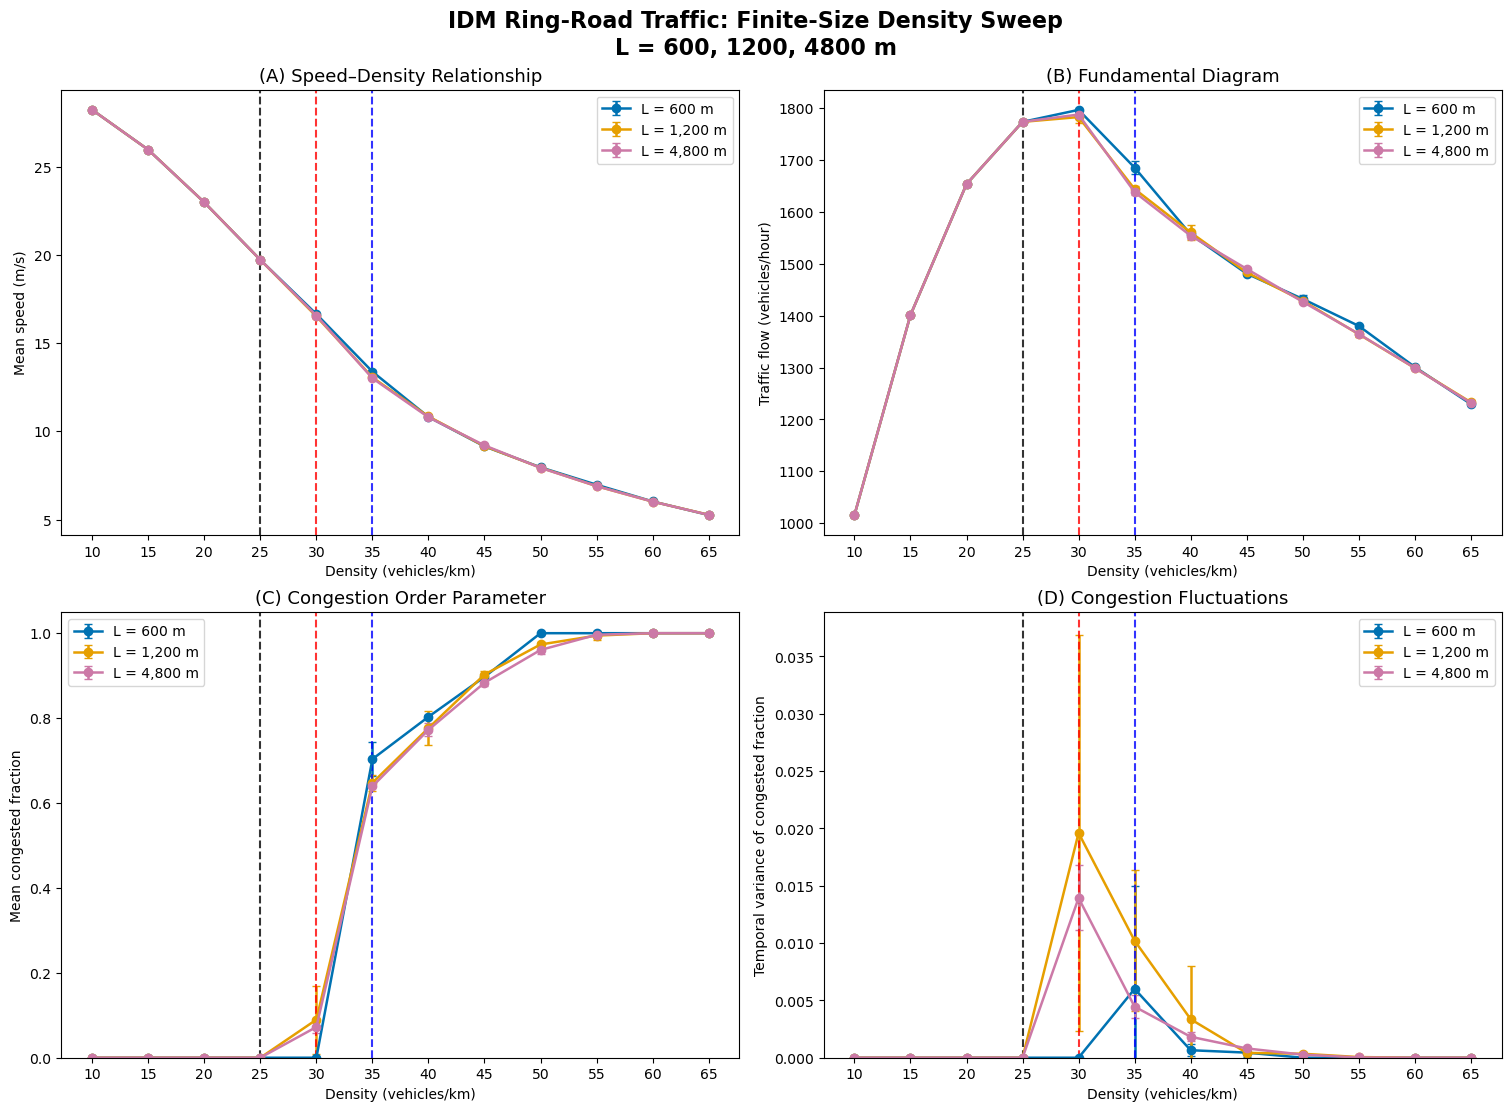

In [64]:
# To plot some figures for analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)

plot_config = [
    {"metric": "mean_speed_mps", "title": "(A) Speed–Density Relationship", "ylabel": "Mean speed (m/s)"},
    {"metric": "flow_veh_h", "title": "(B) Fundamental Diagram", "ylabel": "Traffic flow (vehicles/hour)"},
    {"metric": "congested_fraction", "title": "(C) Congestion Order Parameter", "ylabel": "Mean congested fraction"},
    {"metric": "congested_fraction_var", "title": "(D) Congestion Fluctuations", "ylabel": "Temporal variance of congested fraction"}
]

ring_lengths = [600, 1200, 4800]

colors = {
    600:  "#0072B2",  # Blue
    1200: "#E69F00",  # Orange
    4800: "#CC79A7"   # Reddish purple
}

for ax, config in zip(axes.flat, plot_config):

    metric = config["metric"]

    for length in ring_lengths:

        subset = summary[summary["ring_length_m"] == length].sort_values("density_veh_km")

        ax.errorbar(subset["density_veh_km"], subset[f"{metric}_mean"], yerr=subset[f"{metric}_std"].fillna(0), marker="o", linewidth=1.8, markersize=6, capsize=3, color=colors[length], label=f"L = {length:,} m")

    # Vertical black dashed line at density = 20
    ax.axvline(x=25, color="black", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.axvline(x=30, color="red", linestyle="--", linewidth=1.5, alpha=0.8)
    ax.axvline(x=35, color="blue", linestyle="--", linewidth=1.5, alpha=0.8)

    ax.set_title(config["title"], fontsize=13)
    ax.set_xlabel("Density (vehicles/km)")
    ax.set_ylabel(config["ylabel"])

    ax.set_xticks([10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65])
    # ax.grid(alpha=0.25)
    ax.legend()

axes[1, 0].set_ylim(bottom=0)
axes[1, 0].set_ylim(top=1.05)
axes[1, 1].set_ylim(bottom=0)

fig.suptitle(
    "IDM Ring-Road Traffic: Finite-Size Density Sweep\n"
    "L = 600, 1200, 4800 m",
    fontsize=16,
    fontweight="bold"
)

plt.show()

In [65]:
# Then to plot the space-time diagram for all the densities
from traffic_project.measurements import iter_fcd

lengths = [600, 1200, 4800]
densities = [25, 30, 35, 40]

seed = 501

time_start = 600
time_end = 1800

spatial_bin = 20
temporal_bin = 10

In [66]:
def load_fcd_for_heatmap(length, n_vehicles, seed):

    run_id = f"ring_IDM_L{length}_n{n_vehicles}_s{seed}"

    fcd_path = ROOT / "runs" / run_id / "fcd.xml"

    if not fcd_path.exists():
        raise FileNotFoundError(
            f"Missing FCD file:\n{fcd_path}\n"
            "Check the seed and run directory."
        )

    records = []

    edge_length = length / 4

    for t, vehicles in iter_fcd(fcd_path):

        if not (time_start <= t < time_end):
            continue

        for vehicle in vehicles:

            edge_id = vehicle["lane"].rsplit("_", 1)[0]

            if edge_id not in {"e0", "e1", "e2", "e3"}:
                raise ValueError(f"Unexpected edge ID: {edge_id}")

            edge_index = int(edge_id[1:])

            x = (edge_index * edge_length + vehicle["pos"]) % length

            records.append({
                "time": t,
                "position": x,
                "speed": vehicle["speed"]
            })

    if not records:
        raise ValueError(f"No trajectory observations in {fcd_path}")

    return pd.DataFrame(records)

In [67]:
def make_speed_matrix(df, length, spatial_bin=50, temporal_bin=10):

    n_space = int(np.ceil(length / spatial_bin))
    n_time = int(np.ceil((time_end - time_start) / temporal_bin))

    df = df.copy()

    df["space_idx"] = np.floor(
        df["position"] / spatial_bin
    ).astype(int).clip(0, n_space - 1)

    df["time_idx"] = np.floor(
        (df["time"] - time_start) / temporal_bin
    ).astype(int).clip(0, n_time - 1)

    matrix = (
        df.groupby(["time_idx", "space_idx"])["speed"]
        .mean()
        .unstack()
        .reindex(
            index=range(n_time),
            columns=range(n_space)
        )
    )

    return matrix.to_numpy()

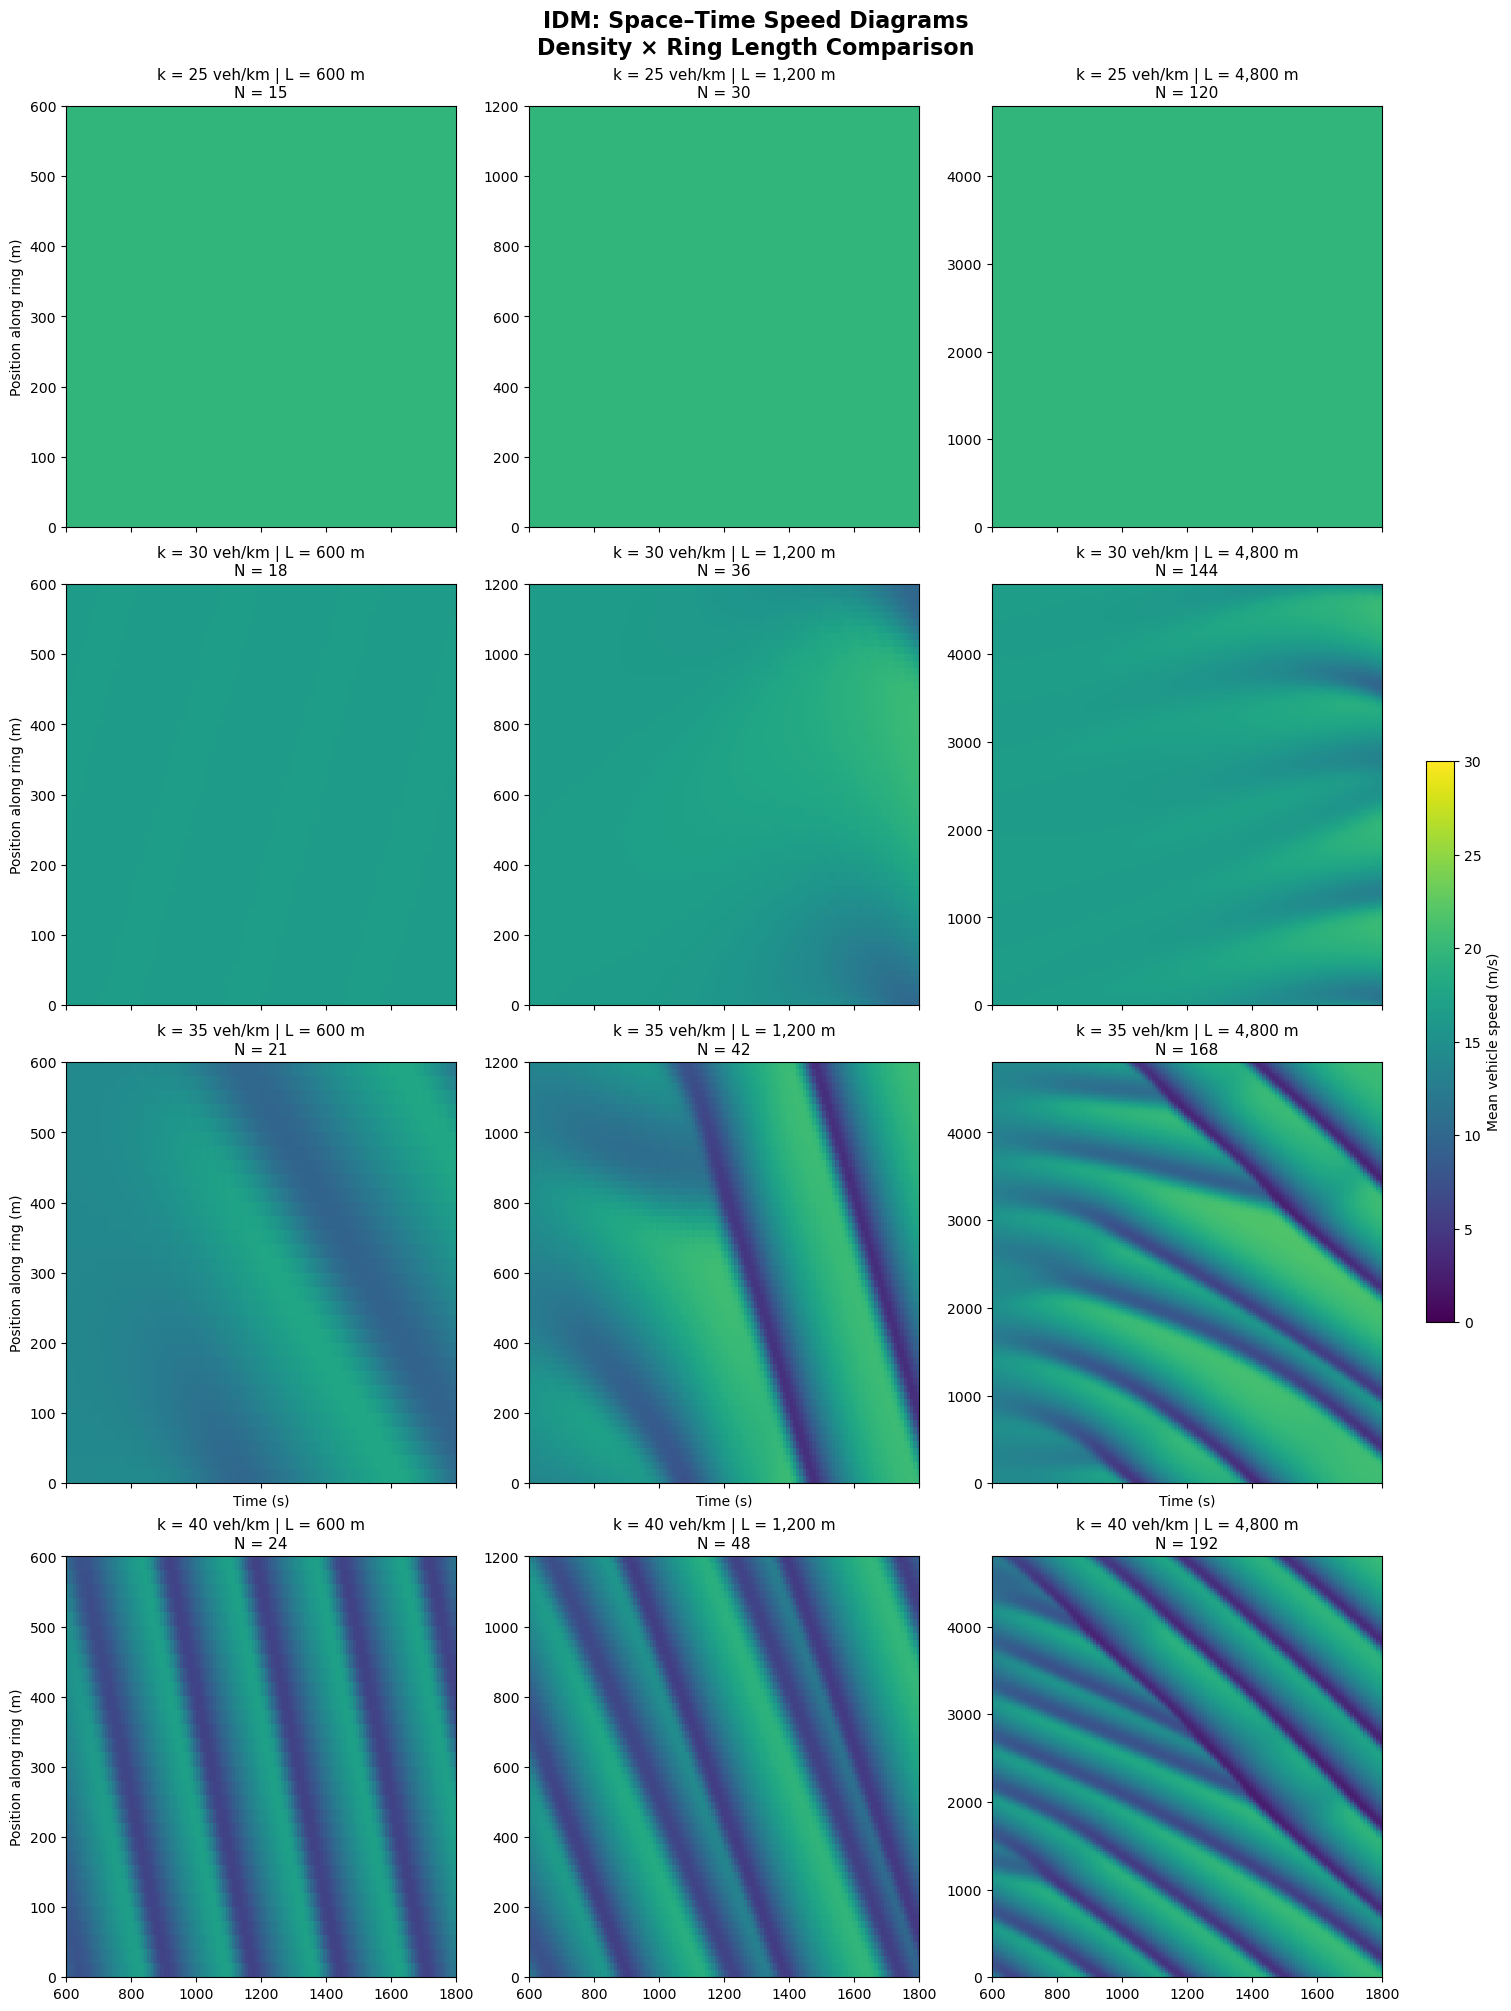

In [68]:
n_rows = len(densities)
n_cols = len(lengths)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 20), sharex=True, constrained_layout=True)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")

for row, density in enumerate(densities):

    for col, length in enumerate(lengths):
        ax = axes[row, col]
        n_vehicles = int(density * length / 1000)
        df = load_fcd_for_heatmap(length, n_vehicles, seed)

        matrix = make_speed_matrix(
            df,
            length,
            spatial_bin=spatial_bin,
            temporal_bin=temporal_bin
        )

        im = ax.imshow(
            np.ma.masked_invalid(matrix.T),
            origin="lower",
            aspect="auto",
            extent=[time_start, time_end,0,length],
            cmap=cmap, vmin=0, vmax=30,
            interpolation="nearest"
        )

        ax.set_title(f"k = {density} veh/km | L = {length:,} m\n"
                     f"N = {n_vehicles}", fontsize=11)

        if col == 0:
            ax.set_ylabel("Position along ring (m)")

        if row == 2:
            ax.set_xlabel("Time (s)")

fig.colorbar(im, ax=axes, label="Mean vehicle speed (m/s)",shrink=0.3, pad=0.02)
fig.suptitle("IDM: Space–Time Speed Diagrams\n" "Density × Ring Length Comparison", fontsize=16, fontweight="bold")
plt.show()

#### Experiment 2: As with the others, the value for sensivity is driven by delta or acceleration
1. To perform a sweep to see there is any changes for acceleration 
2. Since lower a is slower recovery from disturbances and for the disturbance to grow
3. And the higher a is faster recovery and that causes the disturbances to decay - meaning that stop-anf-go waves will disapper
4. Also the desired headway T, if T is small, then vehicles acept more gaps, and potentially less stable, big t distrubances are damped.
5. Since density = 35 shows the most prominent start-stop-go, let see is acceleration sweep can influence it, hypothesis is that increasing a increasing the recovery and then the stop-start disappears

In [121]:
ROOT = Path.cwd().resolve().parent

files = {
    0.5: "IDM_accel_L1200_N42_a0p5.csv",
    0.75: "IDM_accel_L1200_N42_a0p75.csv",
    1.0: "IDM_accel_L1200_N42_a1.csv",
    1.25: "IDM_accel_L1200_N42_a1p25.csv",
    1.5: "IDM_accel_L1200_N42_a1p5.csv",
    2.0: "IDM_accel_L1200_N42_a2.csv"
}

frames = []

for length, filename in files.items():
    path = ROOT / "results" / "ring" / filename

    df = pd.read_csv(path)
    df["accelerate"] = length
    frames.append(df)

df_accelerate = pd.concat(frames, ignore_index=True)

In [122]:
df_accelerate = df_accelerate[df_accelerate["valid"] == True].copy()

metrics = ["mean_speed_mps", "flow_veh_h", "congested_fraction", "congested_fraction_var"]

summary_accelerate = (
    df_accelerate
    .groupby("accelerate")
    .agg(
        **{
            f"{metric}_mean": (metric, "mean")
            for metric in metrics
        },
        **{
            f"{metric}_std": (metric, "std")
            for metric in metrics
        },
        n_seeds=("seed", "nunique")
    )
    .reset_index()
    .sort_values("accelerate")) 

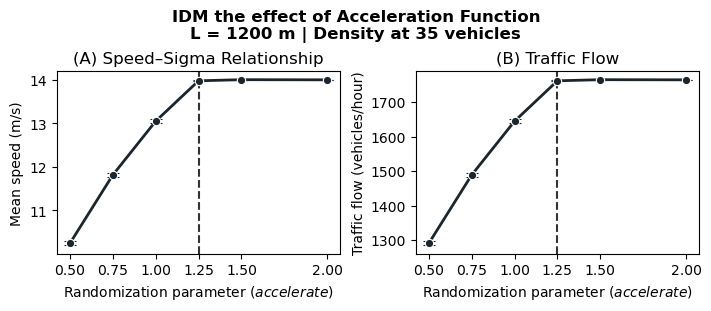

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)

plot_config = [
    {
        "metric": "mean_speed_mps",
        "title": "(A) Speed–Sigma Relationship",
        "ylabel": "Mean speed (m/s)"
    },
    {
        "metric": "flow_veh_h",
        "title": "(B) Traffic Flow",
        "ylabel": "Traffic flow (vehicles/hour)"
    }
]

# Publication-style color
line_color = "#1B252B"

for ax, config in zip(axes.flat, plot_config):

    metric = config["metric"]

    ax.errorbar(summary_accelerate["accelerate"], summary_accelerate[f"{metric}_mean"],
        yerr=summary_accelerate[f"{metric}_std"].fillna(0), marker="o", linestyle="-",
        linewidth=2, markersize=6, capsize=4,
        capthick=1.2, elinewidth=1.2, color=line_color, markeredgecolor="white", markeredgewidth=0.8
    )

    ax.set_title(config["title"], fontsize=12)

    ax.set_xlabel(r"Randomization parameter ($accelerate$)")
    ax.set_ylabel(config["ylabel"])

    ax.set_xticks(sorted(files.keys()))
    ax.axvline(x=1.25, color="black", linestyle="--", linewidth=1.5, alpha=0.8)

fig.suptitle(
    "IDM the effect of Acceleration Function\n"
    r"L = 1200 m | Density at 42 vehicles, k = 35",
    fontsize=12,
    fontweight="bold"
)

plt.show()

In [124]:
def load_fcd_for_accelerate(seed, accelerate):

    acc_str = f"{accelerate:.2f}".replace(".", "p")

    run_id = f"ring_idm_accel-{acc_str}_L1200_n42_s{seed}"

    fcd_path = ROOT / "runs" / run_id / "fcd.xml"

    if not fcd_path.exists():
        raise FileNotFoundError(
            f"Missing FCD file:\n{fcd_path}\n"
            "Check the accelerate, seed and run directory."
        )

    records = []

    length = 1200
    edge_length = length / 4

    for t, vehicles in iter_fcd(fcd_path):

        if not (time_start <= t < time_end):
            continue

        for vehicle in vehicles:

            edge_id = vehicle["lane"].rsplit("_", 1)[0]

            if edge_id not in {"e0", "e1", "e2", "e3"}:
                raise ValueError(f"Unexpected edge ID: {edge_id}")

            edge_index = int(edge_id[1:])

            x = (edge_index * edge_length + vehicle["pos"]) % length

            records.append({
                "time": t,
                "position": x,
                "speed": vehicle["speed"]
            })

    if not records:
        raise ValueError(f"No trajectory observations in {fcd_path}")

    return pd.DataFrame(records)

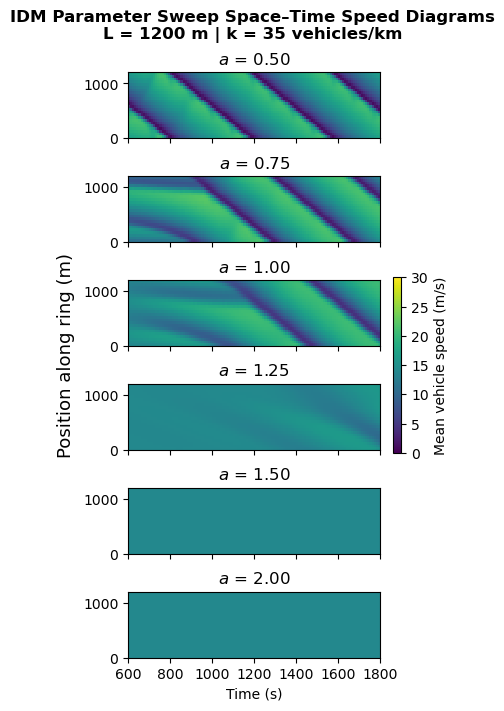

In [ ]:
accelerate = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]

length = 1200
seed = 501

time_start = 600
time_end = 1800

spatial_bin = 50
temporal_bin = 10

n_rows = len(accelerate)

fig, axes = plt.subplots(n_rows, 1, figsize=(4, 7),sharex=True, constrained_layout=True)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")

for row, accelerate in enumerate(accelerate):

    ax = axes[row]

    df = load_fcd_for_accelerate(seed, accelerate)

    matrix = make_speed_matrix(
        df, length, spatial_bin=spatial_bin, temporal_bin=temporal_bin)

    im = ax.imshow(np.ma.masked_invalid(matrix.T), origin="lower", aspect="auto",
        extent=[time_start, time_end, 0, length],
        cmap=cmap, vmin=0, vmax=30,
        interpolation="nearest"
    )

    ax.set_title(rf"$a$ = {accelerate:.2f}", fontsize=12)

    if row == n_rows - 1:
        ax.set_xlabel("Time (s)")

fig.supylabel("Position along ring (m)", fontsize=13)

fig.colorbar(im,ax=axes, label="Mean vehicle speed (m/s)", shrink=0.3, pad=0.02)

fig.suptitle(
    "IDM Parameter Sweep Space–Time Speed Diagrams\n"
    r"L = 1200 m | Density at 42 vehicles, k = 35",
    fontsize=12,
    fontweight="bold"
)

plt.show()

Due to parameter of jam_speed_mps being 15, the calculated is still below and that still indicates jammed fraction.

Flow peaks around 30 veh/km.
Congested fraction starts increasing between approximately 25 and 35 veh/km.
Fluctuations peak around 30–35 veh/km.
At 30 veh/km, longer rings develop disturbances that the 600 m ring cannot support.
At 35 and 40 veh/km, coherent backward-moving waves appear - this further shows the finite-size emergence
Maybe warm-up time is insufficient?
Damping occurs at higher a